# 01 · Exploratory data analysis

Daily Italian gas demand in 2023 from Snam's public **Dati Operativi** report.

**Target:** `RICONSEGNATO` = total gas delivered from the national transmission network (MWh per gas day, 06:00–06:00).

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

import data, model, plots
plots.set_style()
gwh = FuncFormatter(lambda x, _: f"{x/1e3:,.0f}")

In [2]:
daily = data.build_daily()
daily.to_csv(data.PROCESSED_FILE)
print(f"{len(daily)} gas days: {daily.index.min():%d %b %Y} – {daily.index.max():%d %b %Y}")
daily.head()

365 gas days: 31 Dec 2022 – 30 Dec 2023


,demand,hdd,demand_prev_at_issue,hdd_prev_at_issue,demand_today_at_issue,hdd_today_at_issue,snam_forecast,hdd_forecast,is_holiday
date,,,,,,,,,
2022-12-31,1760225.629,8.86,NaN,NaN,NaN,NaN,NaN,NaN,0
2023-01-01,1585921.704,8.70,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-01-02,2025417.957,8.90,1760225.629,8.86,1555222.444,8.62,2137145.927,8.62,0
2023-01-03,2012798.587,8.10,1629270.701,8.70,2024284.378,8.90,2127603.110,8.90,0
2023-01-04,1901233.142,8.27,2025898.938,8.90,1951899.838,8.70,2121247.668,8.70,0


In [3]:
daily[["demand", "hdd"]].describe().round(1)

,demand,hdd
count,365.0,365.0
mean,1774352.0,4.6
std,635601.2,4.8
min,746809.5,0.0
25%,1361083.4,0.0
50%,1632396.9,3.2
75%,2106115.9,8.8
max,3488919.5,16.2


## Demand over the year
Strong seasonality: winter demand is roughly 4× the August minimum. The drop in mid-August is the industrial summer shutdown.

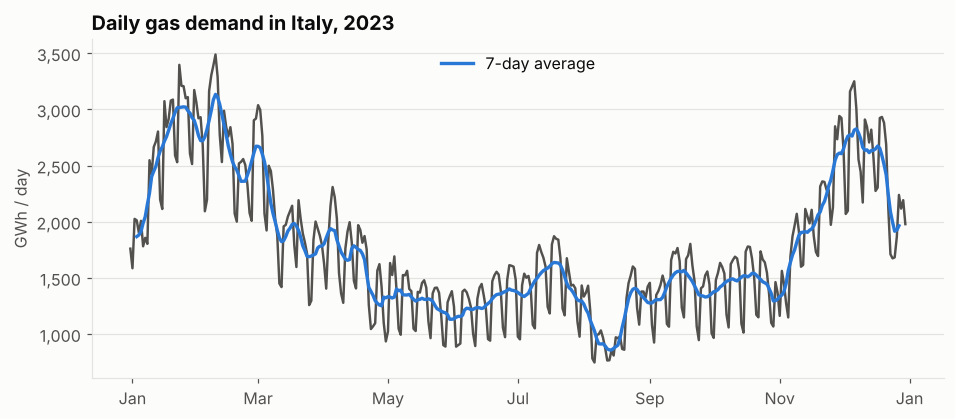

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily["demand"], color=plots.ACTUAL, linewidth=1.6)
ax.plot(daily.index, daily["demand"].rolling(7, center=True).mean(), color=plots.MODEL, linewidth=2.2, label="7-day average")
ax.yaxis.set_major_formatter(gwh)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("GWh / day")
ax.set_title("Daily gas demand in Italy, 2023")
ax.legend(loc="upper center")
plots.save(fig, "demand_2023.png")

## Temperature is the main driver
Heating degree-days (HDD, base 18 °C) measure how cold a day is. Demand grows almost linearly with HDD, and working days sit clearly above weekends and holidays.

Correlation demand–HDD: 0.859


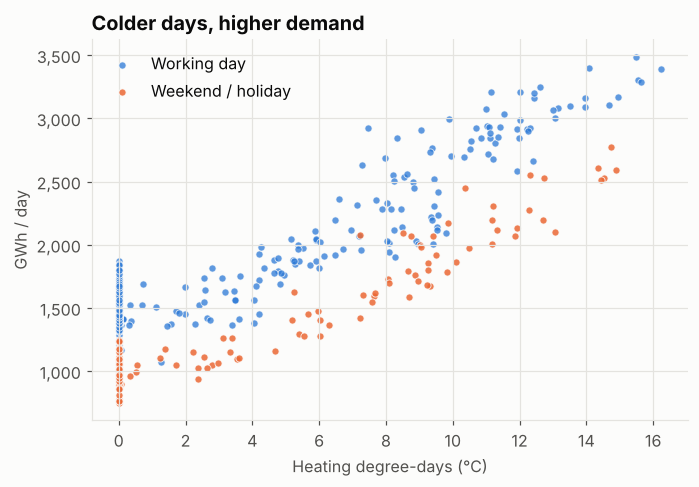

In [5]:
off = (daily.index.dayofweek >= 5) | (daily["is_holiday"] == 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(daily.loc[~off, "hdd"], daily.loc[~off, "demand"], s=22, color=plots.MODEL, alpha=0.75, edgecolor=plots.SURFACE, linewidth=0.6, label="Working day")
ax.scatter(daily.loc[off, "hdd"], daily.loc[off, "demand"], s=22, color=plots.SNAM, alpha=0.85, edgecolor=plots.SURFACE, linewidth=0.6, label="Weekend / holiday")
ax.yaxis.set_major_formatter(gwh)
ax.set_xlabel("Heating degree-days (°C)")
ax.set_ylabel("GWh / day")
ax.set_title("Colder days, higher demand")
ax.grid(axis="x")
ax.legend()
plots.save(fig, "demand_vs_hdd.png")
print("Correlation demand–HDD:", round(daily[["demand", "hdd"]].corr().iloc[0, 1], 3))

## Weekly pattern

In [6]:
dow = daily.groupby(daily.index.dayofweek)["demand"].mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
(dow / dow.mean() * 100 - 100).round(1).rename("% vs weekly mean").to_frame()

,% vs weekly mean
Mon,7.3
Tue,9.0
Wed,10.4
Thu,10.0
Fri,2.3
Sat,-17.1
Sun,-21.8


## Takeaways
- Demand is driven by **temperature** (heating) and by the **calendar** (weekends, holidays, August and Christmas breaks).
- The level changes a lot across the year, so in the forecasting notebook the models predict the **day-to-day change** rather than the level.